# Model comparison: logistic regression, random forest, LightGBM

Train on 2015–2016 vintages, test on 2017 vintages (out-of-time). The label is 180+ days delinquent or a loss exit within 24 months. Every score is reported on all test loans and excluding Florida and Texas, whose 2016–2017 vintages carry the 2017 hurricane forbearance.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve

from fannie_default import models
from fannie_default.evaluate import cost_threshold, importance, oob_score, score_robust
from fannie_default.features import out_of_time_split

REPORTS = Path("../reports")
loans = pd.read_parquet("../data/processed/loans.parquet")
X_train, X_test, y_train, y_test = out_of_time_split(loans)
print(f"train {len(X_train):,} loans ({y_train.mean():.3%} default), test {len(X_test):,} ({y_test.mean():.3%})")

train 421,633 loans (0.213% default), test 181,205 (0.304%)


## Fit

LightGBM holds out the 2016Q4 vintage for early stopping.

In [2]:
valid = (loans.loc[X_train.index, "vintage"] == pd.Period("2016Q4", "Q")).to_numpy()
fitted = {
    "logistic": models.logistic().fit(X_train, y_train),
    "random_forest": models.random_forest().fit(X_train, y_train),
    "lightgbm": models.fit_early_stopped(models.boosting(), X_train, y_train, valid),
}
p = {name: m.predict_proba(X_test)[:, 1] for name, m in fitted.items()}
print("LightGBM trees:", fitted["lightgbm"][-1].best_iteration_)

LightGBM trees: 229


## Scores

In [3]:
metrics = {name: score_robust(y_test, p[name], X_test["STATE"]) for name in fitted}
table = pd.DataFrame({
    (name, subset): m[subset] for name, m in metrics.items() for subset in m
}).T.round(4)
table

roc_auc  pr_auc   brier  base_rate
logistic      all                 0.8324  0.0174  0.2069     0.0030
              excl_storm_states   0.8276  0.0108  0.1652     0.0023
random_forest all                 0.8316  0.0164  0.0472     0.0030
              excl_storm_states   0.8238  0.0099  0.0386     0.0023
lightgbm      all                 0.8316  0.0159  0.0030     0.0030
              excl_storm_states   0.8243  0.0105  0.0023     0.0023

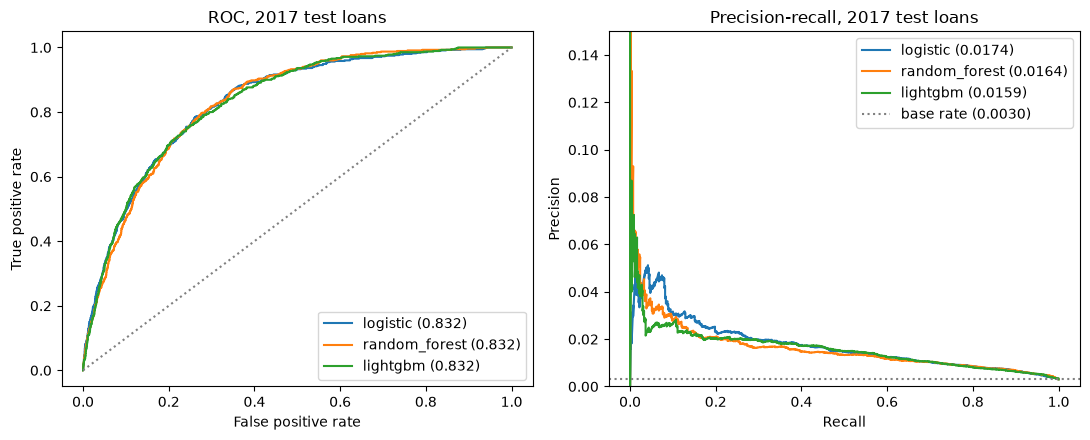

In [4]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.5))
for name, scores in p.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    ax_roc.plot(fpr, tpr, label=f"{name} ({metrics[name]['all']['roc_auc']:.3f})")
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ax_pr.plot(recall, precision, label=f"{name} ({metrics[name]['all']['pr_auc']:.4f})")
ax_roc.plot([0, 1], [0, 1], color="grey", ls=":")
ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC, 2017 test loans")
ax_pr.axhline(y_test.mean(), color="grey", ls=":", label=f"base rate ({y_test.mean():.4f})")
ax_pr.set(xlabel="Recall", ylabel="Precision", title="Precision-recall, 2017 test loans", ylim=(0, 0.15))
ax_roc.legend(); ax_pr.legend()
plt.tight_layout()
plt.savefig(REPORTS / "roc_pr_curves.png", dpi=150)

## Calibration

The logistic and forest models were trained with class weights, which inflate their scores; LightGBM was not. Only a calibrated model's score can be read as a probability of default.

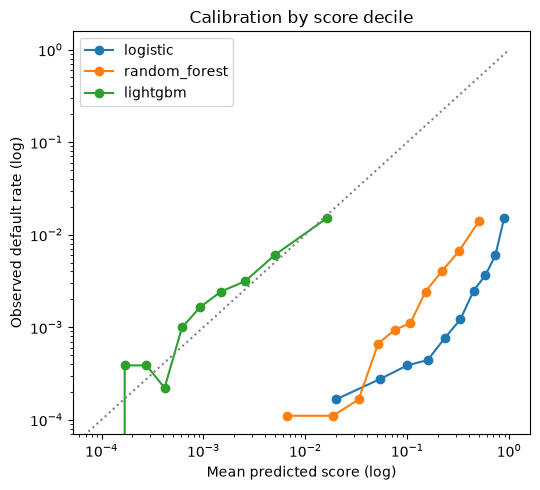

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, scores in p.items():
    frac, mean_pred = calibration_curve(y_test, scores, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", label=name)
ax.plot([0, 1], [0, 1], color="grey", ls=":")
ax.set(xscale="log", yscale="log", xlabel="Mean predicted score (log)", ylabel="Observed default rate (log)",
       title="Calibration by score decile")
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS / "calibration.png", dpi=150)

## Cost-based threshold

Flag a loan when its score is at least the threshold. A missed default costs `cost_fn`, a false alarm `cost_fp`; the threshold minimizes total cost on the test set.

100:1 is the realistic case: a defaulted $200k loan can lose around $50k, while a false alarm costs an extra review or a forgone loan's margin, on the order of hundreds of dollars. 10:1 and 25:1 show how the answer changes when misses are cheaper.

In [6]:
rows = []
for ratio in (10, 25, 100):
    for name, scores in p.items():
        t, cost = cost_threshold(y_test, scores, cost_fn=ratio, cost_fp=1)
        flagged = scores >= t
        rows.append({"cost_fn:cost_fp": f"{ratio}:1", "model": name, "threshold": t, "flagged": flagged.mean(),
                     "defaults caught": (flagged & (y_test == 1)).sum() / y_test.sum(), "total cost": cost})
thresholds = pd.DataFrame(rows)
thresholds.style.format({"threshold": "{:.3f}", "flagged": "{:.2%}", "defaults caught": "{:.1%}", "total cost": "{:,.0f}"})

,cost_fn:cost_fp,model,threshold,flagged,defaults caught,total cost
0,10:1,logistic,inf,0.00%,0.0%,"5,500"
1,10:1,random_forest,0.808,0.01%,0.4%,"5,493"
2,10:1,lightgbm,inf,0.00%,0.0%,"5,500"
3,25:1,logistic,0.975,0.48%,7.5%,"13,557"
4,25:1,random_forest,0.731,0.13%,2.4%,"13,650"
5,25:1,lightgbm,0.070,0.08%,1.6%,"13,659"
6,100:1,logistic,0.835,8.22%,45.1%,"44,841"
7,100:1,random_forest,0.458,6.46%,36.0%,"46,716"
8,100:1,lightgbm,0.009,7.85%,44.4%,"44,581"


## What drives the predictions (LightGBM, permutation importance on test)

CSCORE_B      0.1134
STATE         0.0316
DTI           0.0129
NUM_BO        0.0126
ORIG_RATE     0.0099
OLTV          0.0073
CSCORE_C      0.0063
ORIG_UPB      0.0061
PURPOSE       0.0046
OCLTV         0.0031
OCC_STAT      0.0021
PROP          0.0020
MI_PCT        0.0013
CHANNEL       0.0006
ORIG_TERM     0.0005
FIRST_FLAG    0.0002
NO_UNITS     -0.0003
dtype: float64

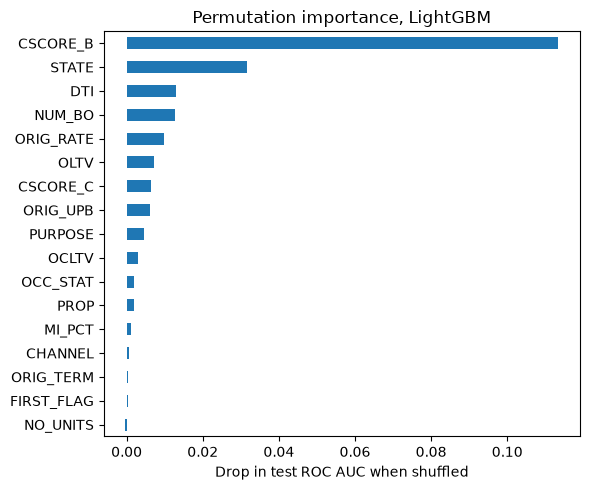

In [7]:
imp = importance(fitted["lightgbm"], X_test, y_test, n_repeats=5)
ax = imp.iloc[::-1].plot.barh(figsize=(6, 5))
ax.set(xlabel="Drop in test ROC AUC when shuffled", title="Permutation importance, LightGBM")
plt.tight_layout()
plt.savefig(REPORTS / "importance_lightgbm.png", dpi=150)
imp.round(4)

## In-time vs. out-of-time

In [8]:
oob = oob_score(fitted["random_forest"], y_train)
print(f"random forest OOB ROC AUC (2015-2016 loans): {oob['roc_auc']:.3f}")
print(f"random forest test ROC AUC (2017 loans):      {metrics['random_forest']['all']['roc_auc']:.3f}")
print(f"LightGBM validation AUC (2016Q4 loans):       {fitted['lightgbm'][-1].best_score_['valid_0']['auc']:.3f}")

random forest OOB ROC AUC (2015-2016 loans): 0.859
random forest test ROC AUC (2017 loans):      0.832
LightGBM validation AUC (2016Q4 loans):       0.883


In [9]:
report = {
    "metrics": metrics,
    "thresholds": thresholds.to_dict(orient="records"),
    "random_forest_oob": oob,
    "lightgbm_trees": int(fitted["lightgbm"][-1].best_iteration_),
    "lightgbm_importance": imp.round(5).to_dict(),
    "n_train": len(X_train), "n_test": len(X_test),
}
(REPORTS / "metrics.json").write_text(json.dumps(report, indent=1, default=float))

3484

## Takeaways

- **The three models tie on ranking.** Test ROC AUC is 0.832 for all three, and PR AUC is 0.016–0.017 against a 0.30% base rate (5–6× no skill). When a linear model, a forest and boosting land on the same number, the ceiling is the information in origination data, not the model.
- **The flexible models lean a little more on the hurricanes.** Without Florida and Texas, the forest and LightGBM lose 0.008 of ROC AUC and logistic regression 0.005. `STATE` is LightGBM's second most important input, behind the borrower's credit score.
- **Only LightGBM is calibrated** (Brier 0.003, on the diagonal above), because it was trained without class weights. Its scores can be read as default probabilities; the other two only rank.
- **Whether a model is worth using depends on the cost ratio.** At 10:1 the cheapest policy is to flag no one. At a realistic 100:1, flagging the riskiest ~8% of loans catches ~45% of defaults and cuts total cost by about 19%, with LightGBM narrowly cheapest.
- **Out-of-time drift is real.** The forest scores 0.860 out-of-bag on 2015–2016 loans and LightGBM 0.883 on its 2016Q4 validation slice, but both score 0.832 on 2017 loans. A random train/test split would have overstated performance.